# Visualize New Dynamic-System Candidates

Run `generate_new_dynamic_system_trajectories.py` first. This notebook shows one 3D trajectory per tested regime.

In [1]:
from pathlib import Path
import json

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Line3DCollection

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.3})

DATA_DIR = Path("test_newds_output")
if not (DATA_DIR / "metadata.json").exists():
    DATA_DIR = Path("test_newds") / "test_newds_output"


with open(DATA_DIR / "metadata.json", "r", encoding="utf-8") as f:
    metadata = json.load(f)

trajectories = np.load(DATA_DIR / "trajectories.npy", allow_pickle=True)
trajectory_phi = np.load(DATA_DIR / "trajectory_phi.npy", allow_pickle=True)
trajectory_regime_names = np.load(DATA_DIR / "trajectory_regime_names.npy", allow_pickle=True)

print("DATA_DIR:", DATA_DIR.resolve())
print("trajectories:", trajectories.shape)
print("trajectory_phi:", trajectory_phi.shape)
print("regimes:")
for i, regime in enumerate(metadata["regimes"]):
    print(f"{i:2d}: {regime['name']} | {regime['parameter']} {regime['start']} -> {regime['end']} | boundary {regime['boundary']}")

DATA_DIR: C:\Users\koray\OneDrive\Dokumente\Studium\Master\Heidelberg\Master_Thesis\generate_trainingdata\time_varying_bifurcation_data\test_newds\test_newds_output
trajectories: (10, 30000, 3)
trajectory_phi: (10, 30000, 1)
regimes:
 0: chen_a_regular_to_chaotic | a 22.0 -> 38.0 | boundary 30.0
 1: thomas_b_chaotic_to_regular | b 0.17 -> 0.28 | boundary 0.208
 2: chua_alpha_single_to_double_scroll | alpha 7.5 -> 15.0 | boundary 10.0
 3: genesio_a_regular_to_chaotic | a 3.5 -> 6.5 | boundary 5.2
 4: hindmarsh_rose_I_spiking_to_bursting | I 1.6 -> 3.4 | boundary 2.7


In [2]:
def crossing_index(phi_series):
    flat = np.asarray(phi_series).reshape(-1)
    changes = np.flatnonzero(np.signbit(flat[:-1]) != np.signbit(flat[1:]))
    return int(changes[0] + 1) if changes.size else None


def pick_series_by_regime(names, regime_name, occurrence=0):
    matches = np.flatnonzero(np.asarray(names).astype(str) == regime_name)
    if not len(matches):
        raise ValueError(f"No series for regime {regime_name!r}")
    return int(matches[min(occurrence, len(matches) - 1)])


def colored_3d_line(ax, xyz, color_values, cmap="coolwarm", linewidth=0.9):
    points = xyz.reshape(-1, 1, 3)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    lc = Line3DCollection(segments, cmap=cmap, linewidth=linewidth)
    lc.set_array(color_values[:-1])
    ax.add_collection3d(lc)
    ax.set_xlim(np.nanmin(xyz[:, 0]), np.nanmax(xyz[:, 0]))
    ax.set_ylim(np.nanmin(xyz[:, 1]), np.nanmax(xyz[:, 1]))
    ax.set_zlim(np.nanmin(xyz[:, 2]), np.nanmax(xyz[:, 2]))
    return lc

## One Whole 3D Trajectory Per Candidate

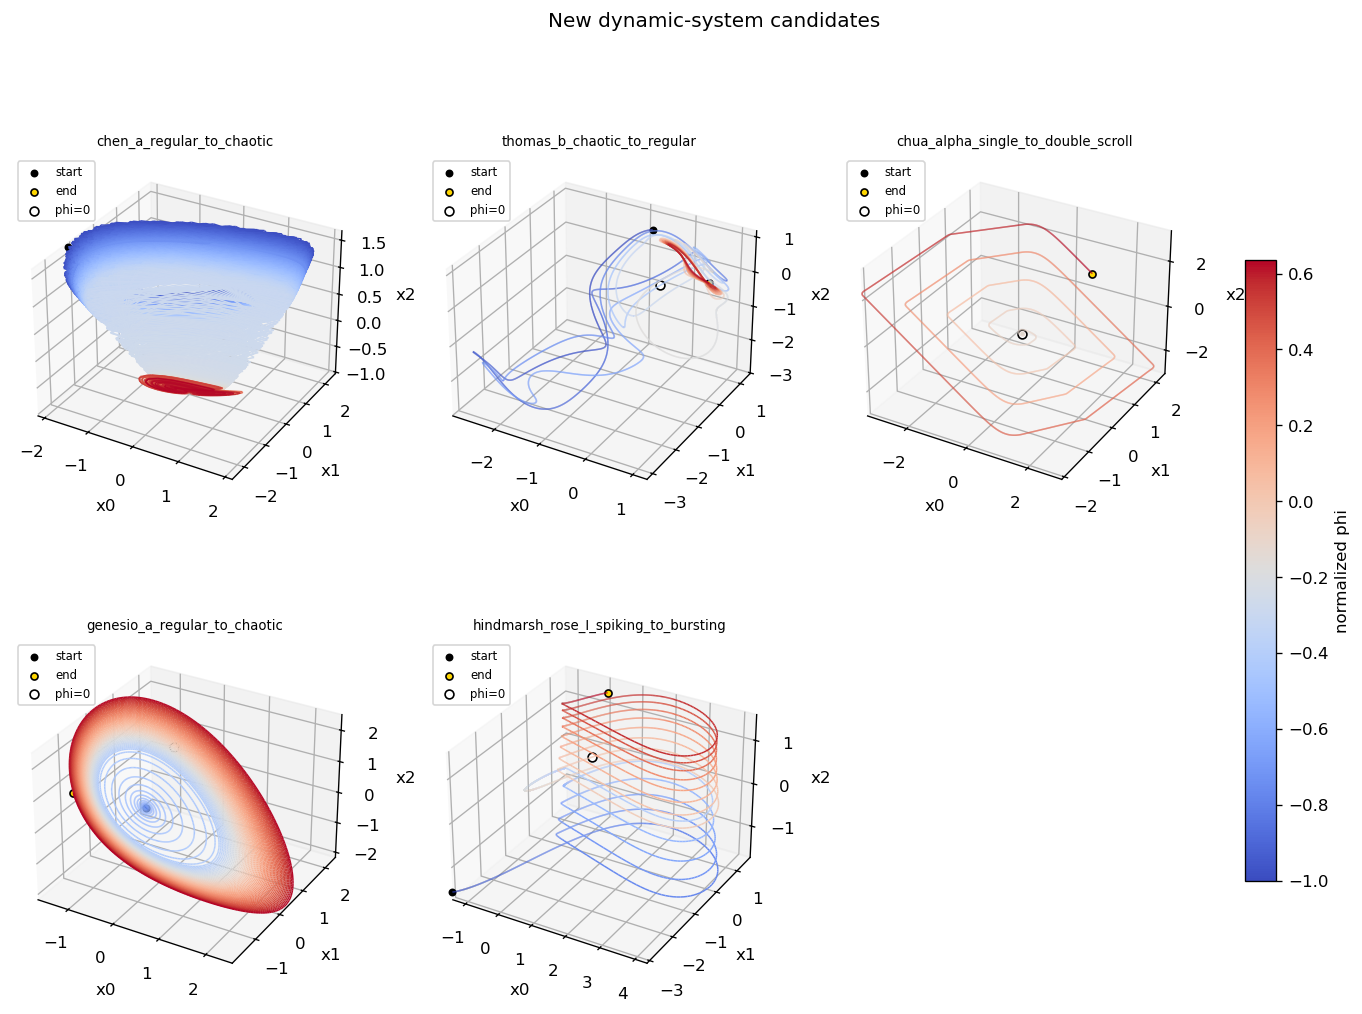

In [3]:
unique_names = list(dict.fromkeys(trajectory_regime_names.astype(str)))
series_indices = [pick_series_by_regime(trajectory_regime_names, name) for name in unique_names]

stride = max(1, trajectories.shape[1] // 12000)
n = len(series_indices)
ncols = min(3, n)
nrows = int(np.ceil(n / ncols))

fig = plt.figure(figsize=(5.2 * ncols, 4.8 * nrows))
axes = []
last_lc = None

for plot_pos, series_index in enumerate(series_indices, start=1):
    ax = fig.add_subplot(nrows, ncols, plot_pos, projection="3d")
    axes.append(ax)

    xyz = trajectories[series_index, ::stride]
    p = trajectory_phi[series_index, ::stride, 0]
    cidx = crossing_index(trajectory_phi[series_index, :, 0])

    last_lc = colored_3d_line(ax, xyz, p)
    ax.scatter(xyz[0, 0], xyz[0, 1], xyz[0, 2], color="black", s=14, label="start")
    ax.scatter(xyz[-1, 0], xyz[-1, 1], xyz[-1, 2], color="gold", edgecolor="black", s=18, label="end")
    if cidx is not None:
        cp = trajectories[series_index, cidx]
        ax.scatter(cp[0], cp[1], cp[2], color="white", edgecolor="black", s=28, label="phi=0")

    ax.set_title(str(trajectory_regime_names[series_index]), fontsize=8)
    ax.set_xlabel("x0")
    ax.set_ylabel("x1")
    ax.set_zlabel("x2")
    ax.legend(loc="upper left", fontsize=7)

if last_lc is not None:
    fig.colorbar(last_lc, ax=axes, pad=0.04, shrink=0.7, label="normalized phi")

fig.suptitle("New dynamic-system candidates", y=0.98)
plt.show()